# Actividad 2 — Análisis de reseñas de hoteles en Punta Cana

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/meendivil/nlp-vision/blob/main/semana-02/Actividad-02/Actividad_2.ipynb)

Puedes ejecutar este notebook localmente (VS Code / Jupyter) o en **Google Colab**.

Si lo abres en Colab, ejecuta primero la celda **Setup para Google Colab** que aparece abajo: instala las dependencias faltantes, descarga el modelo de spaCy, las stopwords de NLTK y baja el dataset `punta_cana.csv` desde el repositorio. En entornos locales esa celda no hace nada y puedes saltarla.

In [32]:
# === Setup para Google Colab ===
# Esta celda solo hace algo cuando el notebook se ejecuta en Google Colab.
# En entornos locales (VS Code / Jupyter) se ignora y puede saltarse.
import sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Dependencias adicionales (Colab ya incluye pandas, sklearn, spacy, nltk)
    # gensim ya no viene preinstalado en Colab; sus binarios requieren numpy 1.x y scipy<1.14
    !pip install -q unidecode "gensim==4.3.3" "scipy==1.13.1" "numpy<2"

    # Modelo de spaCy en español
    !python -m spacy download es_core_news_md -q

    # Stopwords de NLTK
    import nltk
    nltk.download("stopwords", quiet=True)

    # Descarga del dataset desde el repositorio de GitHub
    import os, urllib.request
    BASE = "https://raw.githubusercontent.com/meendivil/nlp-vision/main/semana-02/Actividad-02"
    os.makedirs("data", exist_ok=True)
    for archivo in ["punta_cana.csv"]:
        urllib.request.urlretrieve(f"{BASE}/data/{archivo}", f"data/{archivo}")

    print("Setup de Colab completado.")
else:
    print("Entorno local detectado, no se requiere setup adicional.")

Entorno local detectado, no se requiere setup adicional.


In [33]:
# === Librerías ===

# Datos y utilidades
import re
import time
from collections import Counter
from itertools import chain

import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# NLP clásico
import spacy
import nltk
from nltk.corpus import stopwords
from unidecode import unidecode

# Representación del texto, modelo y métricas
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

# Modelos preentrenados
import torch
from transformers import pipeline

print("Librerías cargadas.")
print("torch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())

Librerías cargadas.
torch 2.14.0+cu130 | CUDA disponible: True


In [34]:
# === Carga del dataset ===

DATA_PATH = "data/punta_cana.csv"

data = pd.read_csv(DATA_PATH)

print(f"Reseñas: {data.shape[0]:,}  |  Columnas: {data.shape[1]}")
print("Columnas:", list(data.columns))
print("\nValores nulos por columna:")
print(data.isna().sum())

data.head()

Reseñas: 34,561  |  Columnas: 6
Columnas: ['hotel_name', 'location', 'wrote', 'rating', 'title', 'review_text']

Valores nulos por columna:
hotel_name        0
location       4371
wrote            47
rating            0
title             0
review_text       0
dtype: int64


,hotel_name,location,wrote,rating,title,review_text
0,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Vacaciones en El paraíso,El hotel impecable todo muy limpio las habitac...
1,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,HOTEL de la EXCELENCIA,"EXCELENTE, magnífico, excepcional, maravilloso..."
2,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Sentirse como en CASA!!!!!,Tras conocer bastantes hoteles en distintos lu...
3,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Muy buen nivel,Muy buen hotel. Cumple con todos los requisito...
4,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,10,Excelente todo ....sobre todo el personal. Es ...


In [35]:
# === Etiquetado de sentimiento a partir de la calificación ===
# Criterio estándar en la industria hotelera:
#   - Positivas (4 y 5): experiencia satisfactoria o excelente, alta probabilidad
#     de recomendación.
#   - Negativas (1, 2 y 3): 1 y 2 son claramente experiencias negativas; el 3 se
#     agrupa aquí porque una valoración intermedia evidencia áreas de mejora y no
#     una experiencia plenamente satisfactoria.
# En este dataset la calificación está en la columna "rating" y el texto de la
# reseña en "review_text".

COL_RATING = "rating"
COL_TEXTO = "review_text"

# Filtrado del DataFrame por calificación
positivas = data[data[COL_RATING].isin([4, 5])]
negativas = data[data[COL_RATING].isin([1, 2, 3])]

# Extracción del texto de cada grupo como listas de Python
textos_positivos = positivas[COL_TEXTO].dropna().astype(str).tolist()
textos_negativos = negativas[COL_TEXTO].dropna().astype(str).tolist()

total = len(textos_positivos) + len(textos_negativos)
print(f"Positivas (4-5): {len(textos_positivos):,} ({len(textos_positivos) / total:.1%})")
print(f"Negativas (1-3): {len(textos_negativos):,} ({len(textos_negativos) / total:.1%})")
print(f"Total etiquetado: {total:,} de {len(data):,} reseñas")

print()
print("Distribución por calificación:")
print(data[COL_RATING].value_counts().sort_index().to_string())

print()
print("Ejemplo positivo:", textos_positivos[0][:160], "...")
print("Ejemplo negativo:", textos_negativos[0][:160], "...")

Positivas (4-5): 30,632 (88.6%)
Negativas (1-3): 3,929 (11.4%)
Total etiquetado: 34,561 de 34,561 reseñas

Distribución por calificación:
rating
1     1334
2      900
3     1695
4     3924
5    26708

Ejemplo positivo: El hotel impecable todo muy limpio las habitaciones amplias y con todo tipo de detalles. Las medidas cocid estaban bien ya que en el bufete tú no tocas nada tod ...
Ejemplo negativo: Estuvimos una semana en el Hotel. Habitaciones. Amplias y confortables. Personal. Atento pero forzado en sus palabras y basado en las propinas especialmente del ...


In [ ]:
# === Unificación y organización de datos ===

data["Sentimiento"] = np.where(data[COL_RATING] >= 4, "positiva", "negativa")

df = data[[COL_TEXTO, "Sentimiento"]].rename(columns={COL_TEXTO: "Comentario"})

print("DataFrame final:", df.shape[0], "filas x", df.shape[1], "columnas")
print("Columnas:", list(df.columns))

print()
print("Reseñas por sentimiento:")
print(df["Sentimiento"].value_counts().to_string())

print()
print("Verificación contra las listas de la celda anterior:")
print(f"  positivas: {(df['Sentimiento'] == 'positiva').sum():,}  |  textos_positivos: {len(textos_positivos):,}")
print(f"  negativas: {(df['Sentimiento'] == 'negativa').sum():,}  |  textos_negativos: {len(textos_negativos):,}")

df.head()

DataFrame final: 34561 filas x 2 columnas
Columnas: ['Comentario', 'Sentimiento']

Reseñas por sentimiento:
Sentimiento
positiva    30632
negativa     3929

Verificación contra las listas de la celda anterior:
  positivas: 30,632  |  textos_positivos: 30,632
  negativas: 3,929  |  textos_negativos: 3,929


,Comentario,Sentimiento
0,El hotel impecable todo muy limpio las habitac...,positiva
1,"EXCELENTE, magnífico, excepcional, maravilloso...",positiva
2,Tras conocer bastantes hoteles en distintos lu...,positiva
3,Muy buen hotel. Cumple con todos los requisito...,positiva
4,Excelente todo ....sobre todo el personal. Es ...,positiva


### Exploración del corpus

Antes de limpiar el texto conviene ver con qué se está trabajando: cómo se reparten las dos clases y qué tan largas son las reseñas.

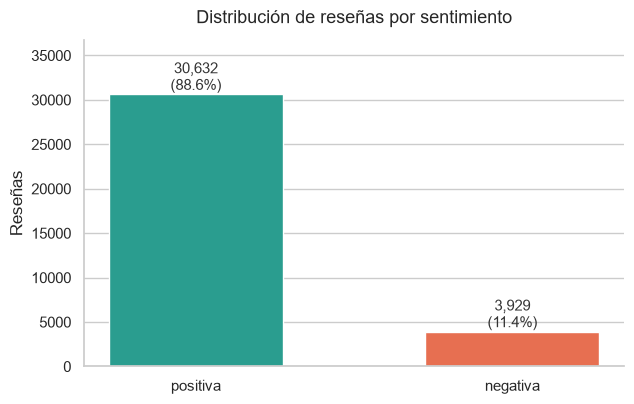

Sentimiento
positiva    30632
negativa     3929
Razón positivas:negativas = 7.8 : 1


In [37]:
# === Distribución de sentimientos ===

sns.set_theme(style="whitegrid")

# Paleta fija por clase: el color sigue a la entidad, nunca a su posición en la
# gráfica, para que "positiva" sea del mismo color en todas las figuras.
COLOR_SENT = {"positiva": "#2a9d8f", "negativa": "#e76f51"}
ORDEN_SENT = ["positiva", "negativa"]

conteo = df["Sentimiento"].value_counts().reindex(ORDEN_SENT)
total = int(conteo.sum())

fig, ax = plt.subplots(figsize=(6.5, 4.2))
barras = ax.bar(conteo.index, conteo.values, width=0.55,
                color=[COLOR_SENT[s] for s in conteo.index])

# Etiqueta directa sobre cada barra: el valor exacto no se lee bien de un eje.
for barra, valor in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor,
            f"{valor:,}\n({valor / total:.1%})",
            ha="center", va="bottom", fontsize=11, color="#333333")

ax.set_title("Distribución de reseñas por sentimiento", fontsize=13, pad=12)
ax.set_ylabel("Reseñas")
ax.set_ylim(0, conteo.max() * 1.20)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

print(conteo.to_string())
print(f"Razón positivas:negativas = {conteo['positiva'] / conteo['negativa']:.1f} : 1")

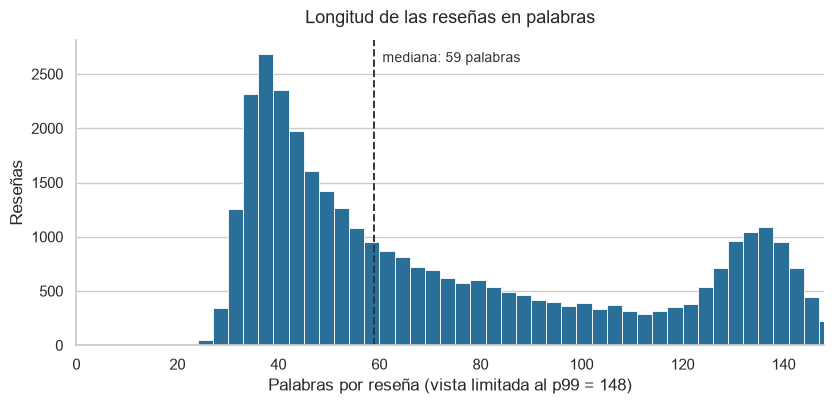

count    34561.0
mean        73.7
std         38.0
min          8.0
25%         41.0
50%         59.0
75%        107.0
max        165.0
Fuera de la vista (> 148 palabras): 294 reseñas (0.9%), la más larga de 165


In [38]:
# === Histograma: longitud de los comentarios ===

sns.set_theme(style="whitegrid")

longitudes = df["Comentario"].str.split().str.len()

# Unas pocas reseñas larguísimas estirarían el eje y aplastarían el resto contra el
# margen izquierdo, así que la vista se limita al percentil 99. Se limita el EJE, no
# los datos: recortar los valores con clip() amontonaría toda la cola en la última
# barra y crearía un pico que no existe.
p99 = longitudes.quantile(0.99)
mediana = longitudes.median()

# Bordes alineados a múltiplos enteros de palabras: con bins automáticos, unos
# intervalos abarcan más valores enteros que otros y el histograma sale en peine.
paso = 3
bordes = np.arange(0, longitudes.max() + paso, paso)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(longitudes, bins=bordes, color="#2a6f97", edgecolor="white", linewidth=0.6)

ax.axvline(mediana, color="#333333", linestyle="--", linewidth=1.4)
ax.text(mediana, ax.get_ylim()[1] * 0.96, f"  mediana: {mediana:.0f} palabras",
        ha="left", va="top", fontsize=10, color="#333333")

ax.set_xlim(0, p99)
ax.set_title("Longitud de las reseñas en palabras", fontsize=13, pad=12)
ax.set_xlabel(f"Palabras por reseña (vista limitada al p99 = {p99:.0f})")
ax.set_ylabel("Reseñas")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

print(longitudes.describe().round(1).to_string())
print(f"Fuera de la vista (> {p99:.0f} palabras): {(longitudes > p99).sum():,} reseñas "
      f"({(longitudes > p99).mean():.1%}), la más larga de {longitudes.max():,}")

## Paso 1. Preprocesamiento del texto

Sobre el corpus de reseñas se aplican las siguientes operaciones:

- Normalización del texto (conversión a minúsculas).
- Eliminación de palabras vacías (stopwords), conservando las negaciones.
- Lematización.
- Eliminación de caracteres especiales (y números).
- Tokenización.

Este procedimiento reduce el ruido del corpus y prepara los datos para su representación estadística del lenguaje.

In [51]:
# === Recursos de lenguaje ===

# Descargar lista de stopwords de NLTK (solo la primera vez)
nltk.download("stopwords")

# Cargar modelo lingüístico de spaCy en español
nlp = spacy.load("es_core_news_md")

# Stopwords en español y conservación de negaciones.
# "no", "ni" y "tampoco" se retiran de la lista de stopwords porque invierten la
# polaridad de la reseña ("no recomiendo" vs. "recomiendo"): eliminarlas haría
# indistinguibles dos opiniones opuestas.
stopwords_es = set(stopwords.words("spanish"))
neg_keep = {"no", "ni", "tampoco"}
stopwords_es = stopwords_es - neg_keep

print(f"Stopwords en español: {len(stopwords_es)} (negaciones conservadas: {sorted(neg_keep)})")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mendi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Stopwords en español: 311 (negaciones conservadas: ['ni', 'no', 'tampoco'])


In [52]:
# === Función de limpieza ===
def clean_text(texto: str, return_str: bool = False):
    """
    Limpia un texto en español (Latinoamérica) usando spaCy + NLTK stopwords:
    - Tokenización
    - Elimina espacios y signos de puntuación
    - Elimina números (dígitos y cantidades escritas con letra)
    - Elimina stopwords (usando la lista de NLTK, conservando las negaciones)
    - Lematiza las palabras
    - Convierte a minúsculas y quita acentos
    - Separa los restos de puntuación pegados dentro de un token y descarta los
      fragmentos vacíos o que resulten ser stopwords

    Devuelve una lista de tokens limpios o una cadena si return_str=True.
    """
    doc = nlp(texto)
    tokens = []
    for t in doc:
        if t.is_space or t.is_punct or t.like_num:
            continue
        lema = t.lemma_.lower()
        if lema in stopwords_es:
            continue
        # Cuando falta el espacio tras un signo ("limpio.La"), spaCy entrega un solo
        # token: se parte por cualquier carácter que no sea letra o dígito y se vuelve
        # a filtrar cada fragmento (así "limpio.la" queda en "limpio" y se descarta "la").
        for fragmento in re.split(r"[\W_]+", lema):
            if not fragmento or fragmento.isdigit() or fragmento in stopwords_es:
                continue
            tokens.append(unidecode(fragmento))
    return " ".join(tokens) if return_str else tokens

In [ ]:
# === Aplicación de la limpieza ===
df["Tokens"] = df["Comentario"].apply(lambda x: clean_text(x))

print("Reseñas tokenizadas:", df["Tokens"].notna().sum())
print("Tokens totales:", int(df["Tokens"].str.len().sum()))
print("Promedio de tokens por reseña:", round(df["Tokens"].str.len().mean(), 1))

df.head()

Reseñas tokenizadas: 34561
Tokens totales: 1402607
Promedio de tokens por reseña: 40.6


,Comentario,Sentimiento,Tokens,Texto_limpio
0,El hotel impecable todo muy limpio las habitac...,positiva,"[hotel, impecable, limpio, habitacion, amplio,...",hotel impecable limpio habitacion amplio tipo ...
1,"EXCELENTE, magnífico, excepcional, maravilloso...",positiva,"[excelente, magnifico, excepcional, maravillos...",excelente magnifico excepcional maravilloso ad...
2,Tras conocer bastantes hoteles en distintos lu...,positiva,"[tras, conocer, bastante, hotel, distinto, lug...",tras conocer bastante hotel distinto lugar mun...
3,Muy buen hotel. Cumple con todos los requisito...,positiva,"[buen, hotel, cumplir, requisito, descansar, s...",buen hotel cumplir requisito descansar ser bie...
4,Excelente todo ....sobre todo el personal. Es ...,positiva,"[excelente, personal, ser, diferenciar, resort...",excelente personal ser diferenciar resort aqui...


### Palabras más frecuentes por sentimiento

Con el texto ya lematizado y sin stopwords se puede ver qué vocabulario caracteriza a cada clase. Las frecuencias se normalizan a **apariciones por cada 1,000 tokens**: hay mucho más texto positivo que negativo, así que los conteos brutos no serían comparables entre los dos paneles.

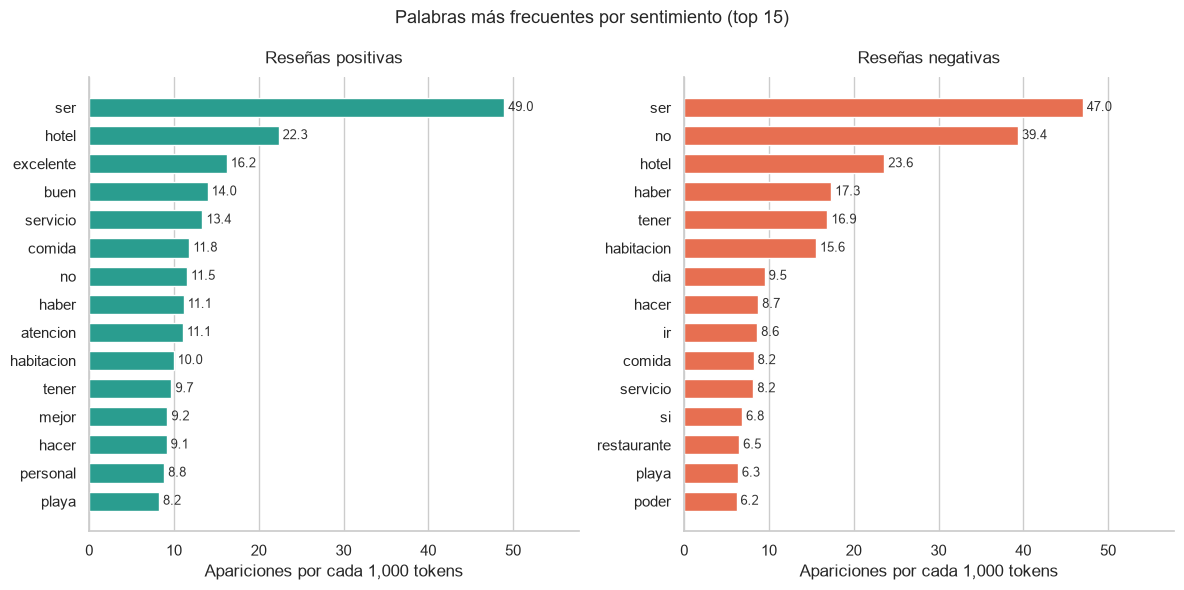

Exclusivos del top positivo: ['atencion', 'buen', 'excelente', 'mejor', 'personal']
Exclusivos del top negativo: ['dia', 'ir', 'poder', 'restaurante', 'si']


In [ ]:
# === Palabras más frecuentes por sentimiento (barras horizontales) ===

sns.set_theme(style="whitegrid")

COLOR_SENT = {"positiva": "#2a9d8f", "negativa": "#e76f51"}
ORDEN_SENT = ["positiva", "negativa"]

TOP_N = 15

frecuencias, totales = {}, {}
for sentimiento in ORDEN_SENT:
    tokens = chain.from_iterable(df.loc[df["Sentimiento"] == sentimiento, "Tokens"])
    frecuencias[sentimiento] = Counter(tokens)
    totales[sentimiento] = sum(frecuencias[sentimiento].values())

# Frecuencia normalizada por cada 1,000 tokens, para que los dos paneles se
# puedan comparar directamente pese al desbalance del corpus.
tops = {}
for sentimiento in ORDEN_SENT:
    pares = frecuencias[sentimiento].most_common(TOP_N)
    tops[sentimiento] = [(p, c / totales[sentimiento] * 1000) for p, c in pares]

# Misma escala en ambos paneles: si cada uno tuviera la suya, barras de largo
# parecido representarían frecuencias distintas.
tope_x = max(v for t in tops.values() for _, v in t) * 1.18

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, sentimiento in zip(axes, ORDEN_SENT):
    palabras = [p for p, _ in tops[sentimiento]][::-1]
    valores = [v for _, v in tops[sentimiento]][::-1]

    ax.barh(palabras, valores, height=0.68, color=COLOR_SENT[sentimiento])
    for y, v in enumerate(valores):
        ax.text(v, y, f" {v:.1f}", va="center", fontsize=9, color="#333333")

    ax.set_title(f"Reseñas {sentimiento}s", fontsize=12, pad=10)
    ax.set_xlabel("Apariciones por cada 1,000 tokens")
    ax.set_xlim(0, tope_x)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax)

fig.suptitle(f"Palabras más frecuentes por sentimiento (top {TOP_N})", fontsize=13)
fig.tight_layout()
plt.show()

# Términos que aparecen en un top y no en el otro
set_pos = {p for p, _ in tops["positiva"]}
set_neg = {p for p, _ in tops["negativa"]}
print("Exclusivos del top positivo:", sorted(set_pos - set_neg))
print("Exclusivos del top negativo:", sorted(set_neg - set_pos))

## Paso 2. Representación del texto mediante TF-IDF

Para pasar del texto limpio a números se construyen dos representaciones sobre el mismo corpus:

**Bag of Words (BoW)** — "bolsa de palabras". Cada reseña se convierte en un vector que simplemente cuenta cuántas veces aparece cada término del vocabulario; el orden de las palabras se descarta (de ahí lo de "bolsa"). El resultado es una **matriz documento-término**: una fila por reseña, una columna por término. Es la base de la que parte TF-IDF, y su límite es que una palabra que sale en todas las reseñas (`hotel`) pesa tanto como una que distingue de verdad a una reseña.

**TF-IDF con bigramas** — toma esos mismos conteos (*term frequency*) y los pondera a la baja según en cuántos documentos aparece el término (*inverse document frequency*). Así, lo que sale en todas partes pierde peso y lo característico de cada reseña lo gana. Se usa `ngram_range=(1, 2)`, de modo que el vocabulario incluye tanto palabras sueltas (`limpio`) como secuencias de dos palabras (`no limpio`, `buena ubicacion`), que es lo que permite captar expresiones que una palabra aislada no representa. `max_features=5000` acota el vocabulario a los 5,000 términos más frecuentes, porque al añadir bigramas crece muy rápido.

La celda de BoW se incluye como contraste: sus conteos en crudo muestran qué cambia al ponderar por idf.

In [55]:
# === Bag of Words: matriz documento-término ===

# La columna "Tokens" ya viene tokenizada, sin stopwords y lematizada, así que se
# le indica al vectorizador que NO vuelva a procesar el texto: el analizador de
# identidad recibe la lista de tokens y la devuelve tal cual.
# min_df=5 descarta los términos que aparecen en menos de 5 reseñas (cola de ruido:
# erratas, nombres propios sueltos).
identidad = lambda tokens: tokens

bow_vectorizer = CountVectorizer(analyzer=identidad, min_df=5)
X_bow = bow_vectorizer.fit_transform(df["Tokens"])
vocabulario = bow_vectorizer.get_feature_names_out()

vocab_sin_filtro = len(set(chain.from_iterable(df["Tokens"])))
densidad = X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])

print(f"Matriz documento-término: {X_bow.shape[0]:,} documentos x {X_bow.shape[1]:,} términos")
print(f"Vocabulario: {len(vocabulario):,} términos (de {vocab_sin_filtro:,} sin el filtro min_df)")
print(f"Celdas distintas de cero: {X_bow.nnz:,} ({densidad:.3%} de la matriz)")
print("La matriz se mantiene dispersa: en denso ocuparía",
      f"{X_bow.shape[0] * X_bow.shape[1] * 8 / 1e9:.1f} GB.")

# Términos más frecuentes en todo el corpus según la matriz
conteos = np.asarray(X_bow.sum(axis=0)).ravel()
orden_bow = conteos.argsort()[::-1]

print()
print("Top 10 por conteo (Bag of Words):")
for i in orden_bow[:10]:
    print(f"  {vocabulario[i]:<15} {conteos[i]:>8,}")

# Vista de un recorte de la matriz (solo se densifica lo que se va a mostrar)
top8 = orden_bow[:8]
vista = pd.DataFrame(X_bow[:5].toarray()[:, top8], columns=vocabulario[top8])
vista.insert(0, "Sentimiento", df["Sentimiento"].head(5).values)
vista

Matriz documento-término: 34,561 documentos x 9,766 términos
Vocabulario: 9,766 términos (de 40,235 sin el filtro min_df)
Celdas distintas de cero: 1,164,895 (0.345% de la matriz)
La matriz se mantiene dispersa: en denso ocuparía 2.7 GB.

Top 10 por conteo (Bag of Words):
  ser               68,251
  hotel             31,617
  no                22,329
  excelente         19,620
  buen              17,704
  servicio          17,592
  haber             16,999
  comida            15,756
  habitacion        15,202
  tener             15,198


,Sentimiento,ser,hotel,no,excelente,buen,servicio,haber,comida
0,positiva,2,1,2,0,0,0,1,0
1,positiva,1,3,1,1,0,0,3,0
2,positiva,6,2,0,0,0,3,0,0
3,positiva,3,1,0,1,1,0,1,0
4,positiva,4,0,0,1,0,0,0,0


In [56]:
# === TF-IDF con bigramas: ponderación por rareza ===

# El paso pide bigramas, y "ngram_range" NO se aplica cuando "analyzer" es un
# callable: scikit-learn lo ignora y avisa ("the parameter 'ngram_range' will not
# be used since 'analyzer' is callable"). Por eso los tokens ya limpios se vuelven
# a unir en una cadena y se deja que el analizador por defecto forme los n-gramas.
df["Texto_limpio"] = df["Tokens"].str.join(" ")

# ngram_range=(1, 2) -> unigramas ("limpio") y bigramas ("no limpio").
# max_features=5000  -> con bigramas el vocabulario se dispara, así que se conservan
#                       los 5,000 términos más frecuentes del corpus.
# Nota: el token_pattern por defecto descarta los tokens de una sola letra.
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df["Texto_limpio"])
terminos = tfidf_vectorizer.get_feature_names_out()

n_bigramas = sum(1 for t in terminos if " " in t)
print(f"Matriz TF-IDF: {X_tfidf.shape[0]:,} x {X_tfidf.shape[1]:,}")
print(f"  unigramas: {len(terminos) - n_bigramas:,}  |  bigramas: {n_bigramas:,}")

# Términos con mayor peso DENTRO de un documento concreto
def terminos_con_mayor_peso(posicion, n=8):
    fila = X_tfidf[posicion]
    pares = sorted(zip(fila.indices, fila.data), key=lambda par: -par[1])[:n]
    return [(terminos[i], round(float(peso), 3)) for i, peso in pares]

for etiqueta in ("positiva", "negativa"):
    posicion = int(np.where(df["Sentimiento"].values == etiqueta)[0][0])
    print()
    print(f"--- Reseña {etiqueta} (fila {posicion}) ---")
    print(df["Comentario"].iloc[posicion][:200], "...")
    print("Términos con mayor peso:")
    for termino, peso in terminos_con_mayor_peso(posicion):
        print(f"  {termino:<22} {peso:.3f}")

# Bigramas que más pesan en promedio: las secuencias léxicas que caracterizan al corpus
peso_medio = np.asarray(X_tfidf.mean(axis=0)).ravel()
orden_tfidf = peso_medio.argsort()[::-1]
solo_bigramas = [j for j in orden_tfidf if " " in terminos[j]][:15]

print()
print("Top 15 BIGRAMAS por peso medio TF-IDF:")
for j in solo_bigramas:
    print(f"  {terminos[j]:<28} {peso_medio[j]:.4f}")

# Contraste global: qué sube y qué baja al ponderar por idf.
# El BoW de la celda anterior es solo de unigramas, así que la columna TF-IDF puede
# incluir bigramas que por definición no existen en el conteo de la izquierda.
print()
print(f"{'Top 10 por CONTEO (BoW)':<32}{'Top 10 por PESO MEDIO (TF-IDF)'}")
for i, j in zip(orden_bow[:10], orden_tfidf[:10]):
    print(f"  {vocabulario[i]:<14}{conteos[i]:>8,}        {terminos[j]:<20}{peso_medio[j]:>8.4f}")

Matriz TF-IDF: 34,561 x 5,000
  unigramas: 2,400  |  bigramas: 2,600

--- Reseña positiva (fila 0) ---
El hotel impecable todo muy limpio las habitaciones amplias y con todo tipo de detalles. Las medidas cocid estaban bien ya que en el bufete tú no tocas nada todo te lo sirven ellos . En la piscina y e ...
Términos con mayor peso:
  bufete                 0.290
  servir                 0.245
  hotel impecable        0.184
  continuamente          0.184
  paella                 0.181
  amable divertido       0.177
  playa                  0.175
  mr blue                0.174

--- Reseña negativa (fila 7) ---
Estuvimos una semana en el Hotel. Habitaciones. Amplias y confortables. Personal. Atento pero forzado en sus palabras y basado en las propinas especialmente del turista americano Comida. Mucha de ella ...
Términos con mayor peso:
  americano              0.413
  tipo comida            0.309
  turismo                0.287
  tipo                   0.195
  referencia             0.156


### Qué términos destacan en cada representación

Las dos figuras siguientes ponen en imagen lo que las tablas anteriores imprimieron: primero las secuencias de dos palabras que más pesan en el corpus, y después el contraste entre medir por frecuencia bruta y medir por rareza.

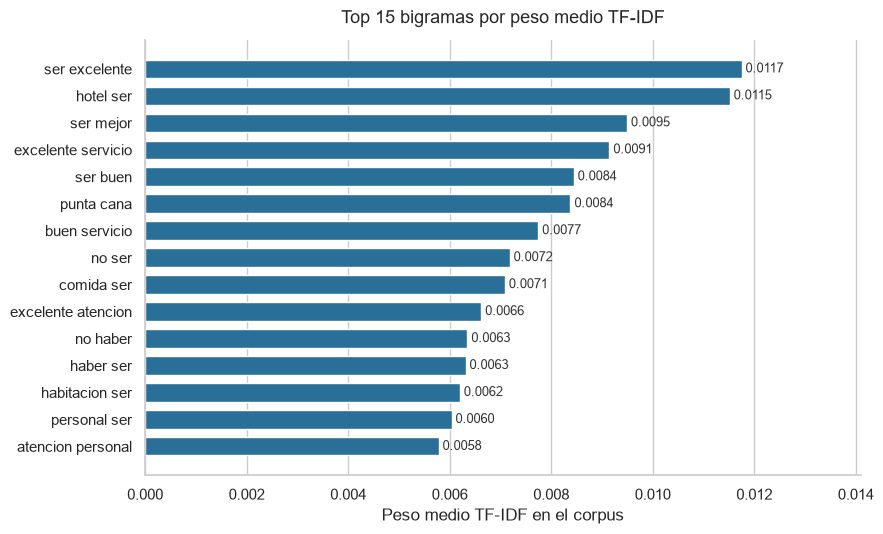

In [57]:
# === Top 15 bigramas por peso medio TF-IDF ===
sns.set_theme(style="whitegrid")

AZUL = "#2a6f97"  # mismo tono que el histograma: serie única, sin identidad por color

bigramas = [terminos[j] for j in solo_bigramas]
pesos_bigramas = [peso_medio[j] for j in solo_bigramas]

# solo_bigramas ya viene de mayor a menor, y barh dibuja de abajo hacia arriba:
# se invierte para que el bigrama más pesado quede en la parte superior.
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(bigramas[::-1], pesos_bigramas[::-1], height=0.68, color=AZUL)

for y, valor in enumerate(pesos_bigramas[::-1]):
    ax.text(valor, y, f" {valor:.4f}", va="center", fontsize=9, color="#333333")

ax.set_title("Top 15 bigramas por peso medio TF-IDF", fontsize=13, pad=12)
ax.set_xlabel("Peso medio TF-IDF en el corpus")
ax.set_xlim(0, max(pesos_bigramas) * 1.20)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

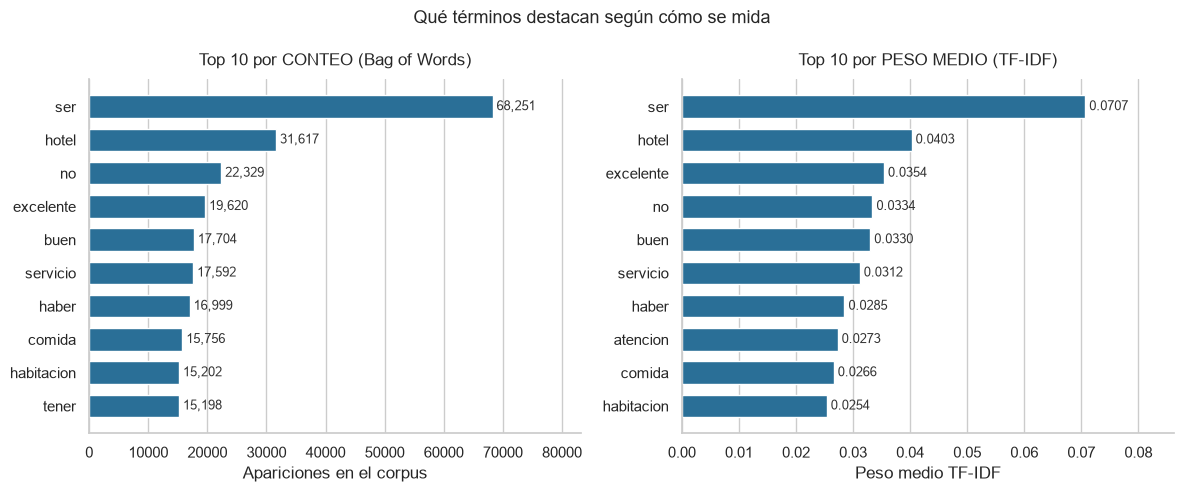

In [58]:
# === Top 10: conteo (BoW) frente a peso medio (TF-IDF) ===
sns.set_theme(style="whitegrid")

AZUL = "#2a6f97"

top_bow = [(vocabulario[i], conteos[i]) for i in orden_bow[:10]]
top_tfidf = [(terminos[j], peso_medio[j]) for j in orden_tfidf[:10]]

# Cada panel mide una cosa distinta (apariciones frente a peso), así que NO comparten
# escala y cada eje lleva su propia unidad: lo comparable entre paneles es el ORDEN de
# los términos, no el largo de las barras.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

paneles = [
    (axes[0], top_bow, "Top 10 por CONTEO (Bag of Words)",
     "Apariciones en el corpus", "{:,.0f}"),
    (axes[1], top_tfidf, "Top 10 por PESO MEDIO (TF-IDF)",
     "Peso medio TF-IDF", "{:.4f}"),
]
for ax, datos, titulo, etiqueta_x, formato in paneles:
    nombres = [t for t, _ in datos][::-1]
    valores = [v for _, v in datos][::-1]

    ax.barh(nombres, valores, height=0.68, color=AZUL)
    for y, valor in enumerate(valores):
        ax.text(valor, y, " " + formato.format(valor), va="center",
                fontsize=9, color="#333333")

    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_xlabel(etiqueta_x)
    ax.set_xlim(0, max(valores) * 1.22)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax)

fig.suptitle("Qué términos destacan según cómo se mida", fontsize=13)
fig.tight_layout()
plt.show()

## Paso 3. Entrenamiento del modelo: regresión logística

La matriz TF-IDF del paso anterior es la entrada (`X`) y la etiqueta de sentimiento es la salida (`y`). El corpus se parte en 80% entrenamiento / 20% prueba y se ajusta una regresión logística, que aprende un peso por término: positivo si empuja la reseña hacia *positiva*, negativo si la empuja hacia *negativa*.

Observaciones sobre este corpus:

- Está **desbalanceado**: 88.6% de las reseñas son positivas. Por eso el split usa `stratify=y`, para que entrenamiento y prueba conserven esa misma proporción.
- Por el mismo desbalance, la **exactitud engaña**: un clasificador que respondiera siempre "positiva" ya acertaría ~88.6%. La celda imprime esa línea base junto a la del modelo para poder juzgarla.

In [85]:
# === Entrenamiento: regresión logística sobre TF-IDF ===

X = X_tfidf            # matriz TF-IDF (unigramas + bigramas)
y = df["Sentimiento"]  # etiqueta: "positiva" / "negativa"

# stratify=y conserva la proporción real de clases en ambas particiones; sin él,
# el muestreo aleatorio podría dejar el conjunto de prueba con una mezcla distinta.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Entrenamiento: {X_train.shape[0]:,} reseñas  |  Prueba: {X_test.shape[0]:,} reseñas")
print("Proporción de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3).to_string())

# max_iter=1000 porque el solver por defecto (lbfgs) no converge en 100 iteraciones
# con un espacio de 5,000 dimensiones.
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# La evaluación por clase va en el paso siguiente; aquí solo se comprueba que el
# modelo aprendió algo por encima de responder siempre la clase mayoritaria.
base = (y_test == "positiva").mean()
print()
print(f"Exactitud en entrenamiento : {model.score(X_train, y_train):.3f}")
print(f"Exactitud en prueba        : {model.score(X_test, y_test):.3f}")
print(f"Línea base (todo positiva) : {base:.3f}")

# Qué aprendió: los términos con mayor peso hacia cada clase.
# model.classes_ viene ordenado alfabéticamente -> coeficiente positivo = "positiva".
coeficientes = model.coef_[0]
orden_coef = coeficientes.argsort()

print()
print(f"(coeficiente > 0 empuja a '{model.classes_[1]}', < 0 a '{model.classes_[0]}')")
print()
print("Términos que más empujan a NEGATIVA:")
for j in orden_coef[:10]:
    print(f"  {terminos[j]:<28} {coeficientes[j]:>7.3f}")
print()
print("Términos que más empujan a POSITIVA:")
for j in orden_coef[::-1][:10]:
    print(f"  {terminos[j]:<28} {coeficientes[j]:>7.3f}")

Entrenamiento: 27,648 reseñas  |  Prueba: 6,913 reseñas
Proporción de clases en entrenamiento:
Sentimiento
positiva    0.886
negativa    0.114

Exactitud en entrenamiento : 0.962
Exactitud en prueba        : 0.952
Línea base (todo positiva) : 0.886

(coeficiente > 0 empuja a 'positiva', < 0 a 'negativa')

Términos que más empujan a NEGATIVA:
  no                            -6.826
  malo                          -5.463
  pesimo                        -5.463
  peor                          -4.784
  mal                           -4.512
  mala                          -3.901
  ni                            -3.498
  horrible                      -3.260
  regular                       -3.210
  no volver                     -3.153

Términos que más empujan a POSITIVA:
  excelente                      6.990
  gracias                        4.003
  perfecto                       3.083
  maravilloso                    3.076
  especial                       3.018
  encantar                       

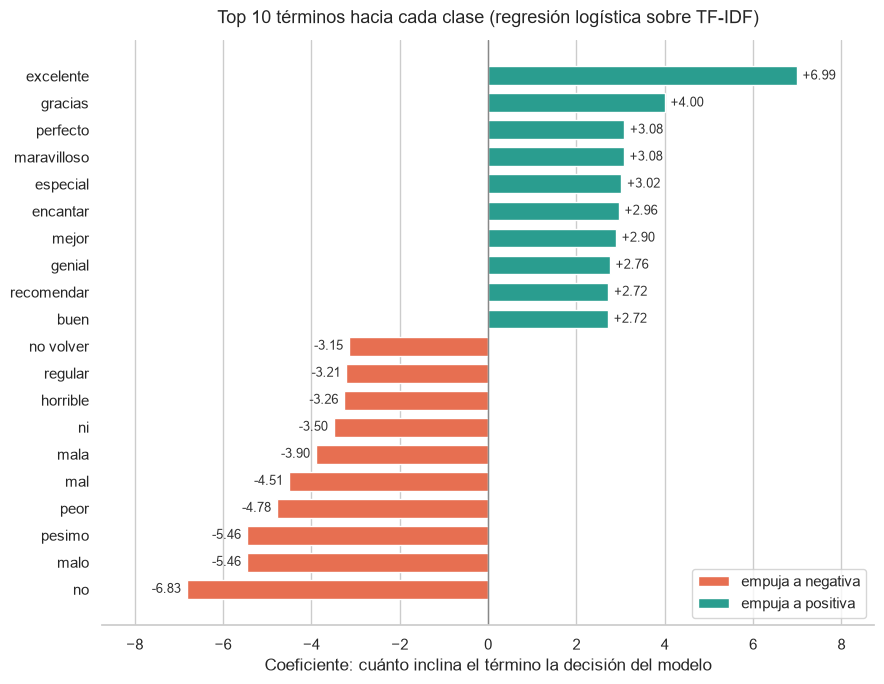

In [86]:
# === Términos con mayor peso en la regresión logística ===
sns.set_theme(style="whitegrid")

COLOR_SENT = {"positiva": "#2a9d8f", "negativa": "#e76f51"}
TOP_N = 10

# orden_coef viene de menor a mayor, así que los primeros son los coeficientes más
# negativos y los últimos los más positivos. Al concatenarlos en ese orden, barh
# dibuja los que empujan a "negativa" abajo y los que empujan a "positiva" arriba.
indices = list(orden_coef[:TOP_N]) + list(orden_coef[-TOP_N:])
etiquetas = [terminos[j] for j in indices]
valores = [coeficientes[j] for j in indices]

fig, ax = plt.subplots(figsize=(9, 7))

# Dos llamadas, una por clase, para que la leyenda se construya sola.
negativos = [(y, v) for y, v in enumerate(valores) if v < 0]
positivos = [(y, v) for y, v in enumerate(valores) if v >= 0]
ax.barh([y for y, _ in negativos], [v for _, v in negativos], height=0.7,
        color=COLOR_SENT["negativa"], label="empuja a negativa")
ax.barh([y for y, _ in positivos], [v for _, v in positivos], height=0.7,
        color=COLOR_SENT["positiva"], label="empuja a positiva")

# El cero es el punto neutro de la escala: un término con coeficiente 0 no inclina
# la decisión hacia ningún lado.
ax.axvline(0, color="#888888", linewidth=1)

limite = max(abs(min(valores)), abs(max(valores))) * 1.25
margen = limite * 0.015
for y, valor in enumerate(valores):
    ax.text(valor + (margen if valor >= 0 else -margen), y, f"{valor:+.2f}",
            va="center", ha="left" if valor >= 0 else "right",
            fontsize=9, color="#333333")

ax.set_yticks(range(len(valores)))
ax.set_yticklabels(etiquetas)
ax.set_xlim(-limite, limite)
ax.set_title(f"Top {TOP_N} términos hacia cada clase (regresión logística sobre TF-IDF)",
             fontsize=13, pad=12)
ax.set_xlabel("Coeficiente: cuánto inclina el término la decisión del modelo")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True)
sns.despine(ax=ax, left=True)
fig.tight_layout()
plt.show()

## Paso 4. Evaluación del modelo

Se evalúa sobre el 20% de prueba, que el modelo no vio durante el entrenamiento:

- **Accuracy** — porcentaje total de aciertos. Con un corpus 88.6% / 11.4% es la métrica menos informativa: responder siempre "positiva" ya la deja en ~0.886.
- **Precision** (por clase) — de lo que el modelo marcó como esa clase, cuánto acertó.
- **Recall** (por clase) — de lo que realmente era esa clase, cuánto encontró. En este corpus es la métrica clave: mide si el modelo detecta las reseñas negativas o las pasa por alto.
- **F1-score** — media armónica de precision y recall; resume ambas en un número.
- **Matriz de confusión** — el desglose de aciertos y errores por celda, que es donde el desbalance se vuelve visible.

In [72]:
# === Evaluación del modelo base ===

y_pred = model.predict(X_test)

print("=== Modelo base: LogisticRegression(max_iter=1000) ===")
print()
print(classification_report(y_test, y_pred, digits=3))

etiquetas = list(model.classes_)  # ['negativa', 'positiva']
cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
cm_df = pd.DataFrame(
    cm,
    index=[f"real: {e}" for e in etiquetas],
    columns=[f"pred: {e}" for e in etiquetas],
)
print("Matriz de confusión:")
print(cm_df.to_string())

# Lectura dirigida: qué pasa con la clase minoritaria
negativas_reales = cm[0].sum()
negativas_detectadas = cm[0, 0]
base = (y_test == "positiva").mean()

print()
print(f"Accuracy del modelo        : {accuracy_score(y_test, y_pred):.3f}")
print(f"Línea base (todo positiva) : {base:.3f}")
print(
    f"Reseñas negativas detectadas: {negativas_detectadas:,} de {negativas_reales:,} "
    f"({negativas_detectadas / negativas_reales:.1%})"
)

=== Modelo base: LogisticRegression(max_iter=1000) ===

              precision    recall  f1-score   support

    negativa      0.873     0.673     0.760       786
    positiva      0.959     0.987     0.973      6127

    accuracy                          0.952      6913
   macro avg      0.916     0.830     0.867      6913
weighted avg      0.949     0.952     0.949      6913

Matriz de confusión:
                pred: negativa  pred: positiva
real: negativa             529             257
real: positiva              77            6050

Accuracy del modelo        : 0.952
Línea base (todo positiva) : 0.886
Reseñas negativas detectadas: 529 de 786 (67.3%)


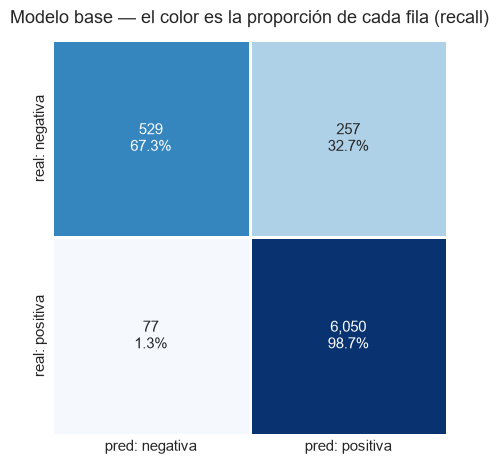

In [73]:
# === Heatmap: matriz de confusión del modelo base ===
sns.set_theme(style="white")

# Mismo criterio que el resto de matrices del notebook: el color codifica la
# proporción POR FILA (el recall de cada clase) y no el conteo, porque con 6,127
# positivas frente a 786 negativas un mapa de conteos pintaría una sola celda.
proporcion = cm / cm.sum(axis=1, keepdims=True)
anotaciones = [
    [f"{cm[i, j]:,}\n{proporcion[i, j]:.1%}" for j in range(cm.shape[1])]
    for i in range(cm.shape[0])
]

fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(
    proporcion, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=1,
    cbar=False, square=True, linewidths=2, linecolor="white",
    xticklabels=[f"pred: {e}" for e in etiquetas],
    yticklabels=[f"real: {e}" for e in etiquetas],
    annot_kws={"fontsize": 11}, ax=ax,
)
ax.set_title("Modelo base — el color es la proporción de cada fila (recall)", fontsize=13, pad=12)
ax.tick_params(length=0)
fig.tight_layout()
plt.show()

### Corrección del desbalance

El modelo base optimiza el error total, y con 88.6% de reseñas positivas la forma más barata de equivocarse poco es inclinarse hacia "positiva". El resultado es una accuracy alta con un recall pobre en la clase negativa: justo el problema que el paso pide identificar.

`class_weight="balanced"` corrige eso pesando cada clase por el inverso de su frecuencia: como las negativas son ~8 veces menos numerosas, cada error sobre una negativa pasa a costar ~8 veces más. El modelo deja de poder ignorarlas.

El intercambio esperado: **sube el recall de negativas y baja su precision** (al marcar más reseñas como negativas, se cuelan falsos positivos), y la accuracy total suele bajar unos puntos. Por eso la comparación se hace sobre F1 y recall de la clase minoritaria, no sobre accuracy.

In [74]:
# === Corrección del desbalance: class_weight="balanced" ===

# Mismo split y mismos hiperparámetros; lo único que cambia es el peso por clase.
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
model_bal.fit(X_train, y_train)
y_pred_bal = model_bal.predict(X_test)

print("=== Modelo balanceado: class_weight='balanced' ===")
print()
print(classification_report(y_test, y_pred_bal, digits=3))

cm_bal = confusion_matrix(y_test, y_pred_bal, labels=etiquetas)
cm_bal_df = pd.DataFrame(
    cm_bal,
    index=[f"real: {e}" for e in etiquetas],
    columns=[f"pred: {e}" for e in etiquetas],
)
print("Matriz de confusión:")
print(cm_bal_df.to_string())

# --- Comparación lado a lado ---
def resumen(nombre, y_true, y_hat):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_hat, labels=["negativa"], zero_division=0
    )
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision (neg)": p[0],
        "Recall (neg)": r[0],
        "F1 (neg)": f[0],
        "F1 macro": f1_score(y_true, y_hat, average="macro"),
    }

comparacion = pd.DataFrame([
    resumen("Base", y_test, y_pred),
    resumen("Balanced", y_test, y_pred_bal),
]).set_index("Modelo")

print()
print("Comparación (clase 'negativa' = la minoritaria):")
print(comparacion.round(3).to_string())

detectadas_bal = cm_bal[0, 0]
print()
print(
    f"Negativas detectadas: {negativas_detectadas:,} -> {detectadas_bal:,} "
    f"de {negativas_reales:,}"
)

=== Modelo balanceado: class_weight='balanced' ===

              precision    recall  f1-score   support

    negativa      0.661     0.910     0.766       786
    positiva      0.988     0.940     0.963      6127

    accuracy                          0.937      6913
   macro avg      0.825     0.925     0.865      6913
weighted avg      0.951     0.937     0.941      6913

Matriz de confusión:
                pred: negativa  pred: positiva
real: negativa             715              71
real: positiva             366            5761

Comparación (clase 'negativa' = la minoritaria):
          Accuracy  Precision (neg)  Recall (neg)  F1 (neg)  F1 macro
Modelo                                                               
Base         0.952            0.873         0.673     0.760     0.867
Balanced     0.937            0.661         0.910     0.766     0.865

Negativas detectadas: 529 -> 715 de 786


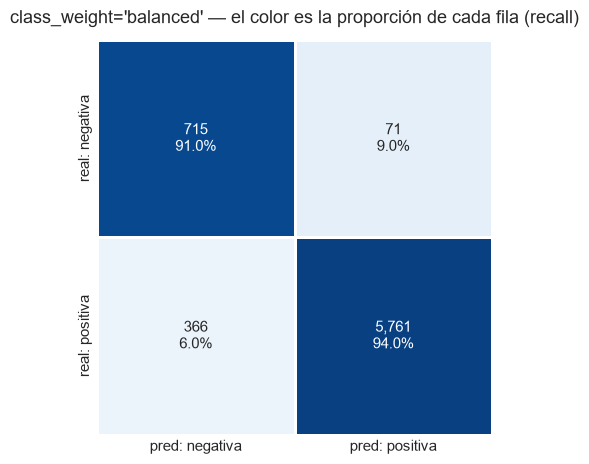

In [75]:
# === Heatmap: matriz de confusión del modelo balanceado ===
sns.set_theme(style="white")

# Mismo criterio que el resto de matrices del notebook: el color codifica la
# proporción POR FILA (el recall de cada clase) y no el conteo, porque con 6,127
# positivas frente a 786 negativas un mapa de conteos pintaría una sola celda.
proporcion = cm_bal / cm_bal.sum(axis=1, keepdims=True)
anotaciones = [
    [f"{cm_bal[i, j]:,}\n{proporcion[i, j]:.1%}" for j in range(cm_bal.shape[1])]
    for i in range(cm_bal.shape[0])
]

fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(
    proporcion, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=1,
    cbar=False, square=True, linewidths=2, linecolor="white",
    xticklabels=[f"pred: {e}" for e in etiquetas],
    yticklabels=[f"real: {e}" for e in etiquetas],
    annot_kws={"fontsize": 11}, ax=ax,
)
ax.set_title("class_weight='balanced' — el color es la proporción de cada fila (recall)", fontsize=13, pad=12)
ax.tick_params(length=0)
fig.tight_layout()
plt.show()

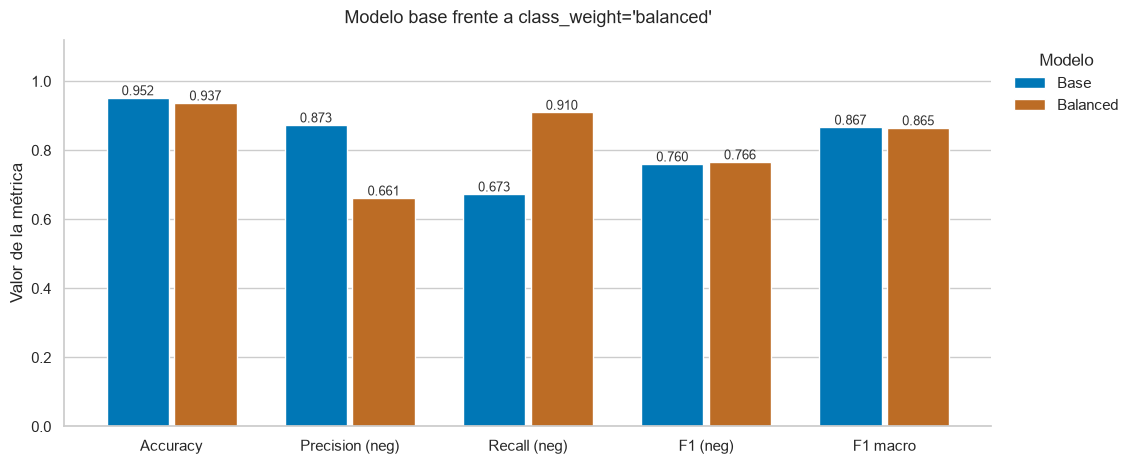

In [76]:
# === Base vs. Balanced en las cinco métricas ===
sns.set_theme(style="whitegrid")

# Dos modelos = dos series, así que hacen falta dos tonos distintos de los que ya
# usa el notebook para los sentimientos: el verde y el naranja significan "positiva"
# y "negativa" en las otras figuras y reutilizarlos aquí diría algo falso.
COLOR_MODELO = {"Base": "#0077b6", "Balanced": "#bc6c25"}

metricas = list(comparacion.columns)
posiciones = np.arange(len(metricas))
ancho = 0.38

fig, ax = plt.subplots(figsize=(11.5, 4.8))
for k, modelo in enumerate(comparacion.index):
    valores = comparacion.loc[modelo].values
    # width algo menor que el paso deja un hueco de fondo entre barras vecinas
    barras = ax.bar(posiciones + (k - 0.5) * ancho, valores, width=ancho * 0.92,
                    color=COLOR_MODELO[modelo], label=modelo)
    for barra, valor in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:.3f}",
                ha="center", va="bottom", fontsize=9, color="#333333")

ax.set_xticks(posiciones)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Modelo base frente a class_weight='balanced'", fontsize=13, pad=12)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, title="Modelo")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

### El desbalance, antes y después de corregirlo

Un detalle importante para leer la siguiente figura: **`class_weight="balanced"` no cambia cuántas reseñas hay**. No duplica las negativas ni descarta positivas — el conjunto de entrenamiento es exactamente el mismo antes y después. Lo que cambia es cuánto *pesa* el error de cada clase en la función de pérdida.

Por eso un count plot del "después" saldría idéntico al del "antes". El segundo panel muestra en su lugar el **peso efectivo** de cada clase (reseñas × peso asignado), que es lo que realmente ve el optimizador: ahí sí las dos clases quedan iguales.

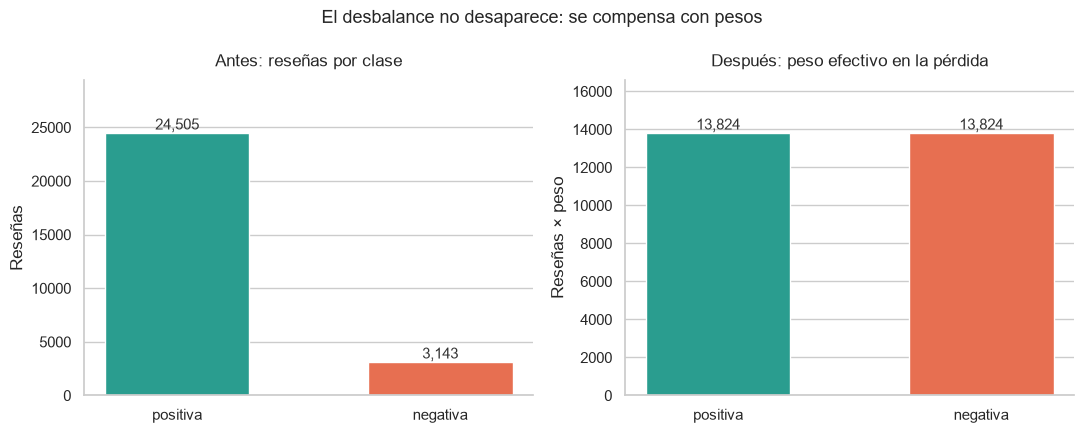

Peso asignado a cada clase por class_weight='balanced':
  positiva  0.564
  negativa  4.398

Reseñas por clase   : {'positiva': np.int64(24505), 'negativa': np.int64(3143)}
Peso efectivo       : {'positiva': 13,824, 'negativa': 13,824}  <- iguales


In [77]:
# === Count plot: desbalance real vs. peso efectivo tras el balanceo ===

sns.set_theme(style="whitegrid")

# Paleta fija por clase: el color sigue a la entidad, nunca a su posición en la
# gráfica, para que "positiva" sea del mismo color en todas las figuras.
COLOR_SENT = {"positiva": "#2a9d8f", "negativa": "#e76f51"}
ORDEN_SENT = ["positiva", "negativa"]

# Panel 1: el conteo real del conjunto de entrenamiento (el desbalance).
conteo_train = y_train.value_counts().reindex(ORDEN_SENT)

# Panel 2: el peso que class_weight="balanced" asigna a cada clase, multiplicado
# por su número de reseñas. Es la "masa" que cada clase aporta a la pérdida.
pesos = compute_class_weight("balanced", classes=np.array(ORDEN_SENT), y=y_train)
peso_por_clase = dict(zip(ORDEN_SENT, pesos))
efectivo = conteo_train * pd.Series(peso_por_clase)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

paneles = [
    (axes[0], conteo_train, "Antes: reseñas por clase", "Reseñas", "{:,.0f}"),
    (axes[1], efectivo, "Después: peso efectivo en la pérdida", "Reseñas × peso", "{:,.0f}"),
]
for ax, serie, titulo, etiqueta_y, formato in paneles:
    barras = ax.bar(serie.index, serie.values, width=0.55,
                    color=[COLOR_SENT[s] for s in serie.index])
    for barra, valor in zip(barras, serie.values):
        ax.text(barra.get_x() + barra.get_width() / 2, valor, formato.format(valor),
                ha="center", va="bottom", fontsize=11, color="#333333")
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_ylabel(etiqueta_y)
    ax.set_ylim(0, serie.max() * 1.20)
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

fig.suptitle("El desbalance no desaparece: se compensa con pesos", fontsize=13)
fig.tight_layout()
plt.show()

print("Peso asignado a cada clase por class_weight='balanced':")
for clase, peso in peso_por_clase.items():
    print(f"  {clase:9s} {peso:.3f}")
print(f"\nReseñas por clase   : {dict(conteo_train)}")
print(f"Peso efectivo       : {{'positiva': {efectivo['positiva']:,.0f}, "
      f"'negativa': {efectivo['negativa']:,.0f}}}  <- iguales")

## Paso 5. Implementación de un modelo basado en Transformers

Hasta aquí el clasificador se construyó desde cero: se limpió el texto, se contaron términos y se ajustó una regresión logística sobre esas cuentas. Un modelo basado en Transformers invierte el planteamiento — ya viene entrenado, y se usa tal cual.

**Qué modelo y por qué.** El ejemplo de la actividad muestra `bert-base-uncased`, que sirve para ilustrar la API pero no para esta tarea: está entrenado en inglés y no tiene cabeza de clasificación de sentimiento (`pipeline` le añadiría una con pesos aleatorios, así que sus predicciones serían ruido). Se usa en su lugar **`finiteautomata/beto-sentiment-analysis`**: BETO es BERT entrenado en español, y esta variante ya está afinada para análisis de sentimiento.

**Tres diferencias frente al modelo clásico:**

- **No hay entrenamiento.** No hay `fit`, ni split, ni vocabulario que construir. Se carga y se predice.
- **Recibe el texto crudo.** Su propio tokenizador (WordPiece) se encarga del texto; no se le pasa la salida del Paso 1. Lematizar y quitar stopwords antes le quitaría justamente el contexto que sabe aprovechar.
- **Lee el orden de las palabras.** "no recomiendo" y "recomiendo" son vectores idénticos en bag of words; para un Transformer son frases distintas.

In [78]:
# === Carga del modelo preentrenado ===

MODELO = "finiteautomata/beto-sentiment-analysis"

# device=0 usa la primera GPU; -1 fuerza CPU. La descarga (~440 MB) ocurre solo la
# primera vez y queda en la caché local de Hugging Face.
usa_gpu = torch.cuda.is_available()
device = 0 if usa_gpu else -1
print("Dispositivo:", torch.cuda.get_device_name(0) if usa_gpu else "CPU")

classifier = pipeline("sentiment-analysis", model=MODELO, device=device)

print("Etiquetas del modelo:", classifier.model.config.id2label)

# Prueba rápida antes de lanzarlo sobre el corpus
ejemplos = [
    "El hotel impecable, todo muy limpio y el personal amabilisimo.",
    "Pesimo servicio, la habitacion estaba sucia y la comida fria.",
    "El hotel esta bien, nada del otro mundo.",
    "No recomiendo este hotel.",
]
for texto, r in zip(ejemplos, classifier(ejemplos)):
    print(f"  {r['label']:4s} {r['score']:.3f}  <- {texto}")

Dispositivo: NVIDIA GeForce RTX 5070 Ti Laptop GPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Etiquetas del modelo: {0: 'NEG', 1: 'NEU', 2: 'POS'}
  POS  0.997  <- El hotel impecable, todo muy limpio y el personal amabilisimo.
  NEG  0.999  <- Pesimo servicio, la habitacion estaba sucia y la comida fria.
  POS  0.998  <- El hotel esta bien, nada del otro mundo.
  NEG  0.980  <- No recomiendo este hotel.


In [79]:
# === Inferencia sobre el conjunto de prueba ===

# Se usan exactamente las mismas reseñas que evaluaron a la regresión logística:
# y_test conserva los índices originales de df, así que basta recuperar su texto.
# Nota: se le pasa el COMENTARIO CRUDO, no los tokens del Paso 1.
textos_test = df.loc[y_test.index, "Comentario"].astype(str).tolist()
print(f"Reseñas a clasificar: {len(textos_test):,}")

# truncation + max_length: BETO admite 512 posiciones; 256 cubre la gran mayoría de
# las reseñas y reduce el cómputo a la mitad.
# Cada modelo tiene su propio limite de longitud y hay que respetarlo: BETO admite
# 512 posiciones, pero RoBERTuito (entrenado con tuits) solo 128. Pasar un max_length
# mayor al del modelo produce indices de posicion fuera de rango, que en GPU aborta
# con "scatter gather kernel index out of bounds".
def longitud_maxima(clf, tope=256):
    return min(tope, clf.tokenizer.model_max_length)


t0 = time.time()
predicciones = classifier(
    textos_test,
    batch_size=64 if usa_gpu else 16,
    truncation=True,
    max_length=longitud_maxima(classifier),
)
transcurrido = time.time() - t0
print(f"Tiempo: {transcurrido:.1f}s  ({len(textos_test)/transcurrido:,.0f} reseñas/s)")

# --- De 3 clases a 2 ---
# BETO devuelve POS / NEU / NEG, pero la etiqueta de este corpus es binaria. NEU se
# mapea a "negativa" por coherencia con el criterio del Paso 1, donde la calificación
# de 3 estrellas (la intermedia) también se contó como negativa.
MAPEO = {"POS": "positiva", "NEU": "negativa", "NEG": "negativa"}
y_pred_beto = pd.Series([MAPEO[p["label"]] for p in predicciones], index=y_test.index)

conteo_crudo = pd.Series([p["label"] for p in predicciones]).value_counts()
print()
print("Distribución de las 3 etiquetas originales del modelo:")
print(conteo_crudo.to_string())

Reseñas a clasificar: 6,913
Tiempo: 28.6s  (241 reseñas/s)

Distribución de las 3 etiquetas originales del modelo:
POS    5854
NEG     623
NEU     436


In [80]:
# === Evaluación de BETO y comparación con el modelo clásico ===
print("=== BETO (preentrenado, sin ajuste sobre este corpus) ===")
print()
print(classification_report(y_test, y_pred_beto, digits=3))

cm_beto = confusion_matrix(y_test, y_pred_beto, labels=etiquetas)
print("Matriz de confusión:")
print(pd.DataFrame(
    cm_beto,
    index=[f"real: {e}" for e in etiquetas],
    columns=[f"pred: {e}" for e in etiquetas],
).to_string())

# resumen() viene de la celda de corrección del desbalance
comparacion_3 = pd.DataFrame([
    resumen("LogReg base", y_test, y_pred),
    resumen("LogReg balanced", y_test, y_pred_bal),
    resumen("BETO", y_test, y_pred_beto),
]).set_index("Modelo")

print()
print("Comparación de los tres modelos (clase 'negativa' = la minoritaria):")
print(comparacion_3.round(3).to_string())

=== BETO (preentrenado, sin ajuste sobre este corpus) ===

              precision    recall  f1-score   support

    negativa      0.620     0.836     0.712       786
    positiva      0.978     0.934     0.956      6127

    accuracy                          0.923      6913
   macro avg      0.799     0.885     0.834      6913
weighted avg      0.937     0.923     0.928      6913

Matriz de confusión:
                pred: negativa  pred: positiva
real: negativa             657             129
real: positiva             402            5725

Comparación de los tres modelos (clase 'negativa' = la minoritaria):
                 Accuracy  Precision (neg)  Recall (neg)  F1 (neg)  F1 macro
Modelo                                                                      
LogReg base         0.952            0.873         0.673     0.760     0.867
LogReg balanced     0.937            0.661         0.910     0.766     0.865
BETO                0.923            0.620         0.836     0.712     0.8

### Generación de predicciones

Con el modelo ya cargado, clasificar un texto es una sola llamada. El `pipeline` devuelve, por cada texto, un diccionario con dos campos:

- **`label`** — la etiqueta de sentimiento predicha.
- **`score`** — la probabilidad asociada, entre 0 y 1, que indica qué tan seguro está el modelo.

Se usa un conjunto fijo de textos de prueba que incluye casos fáciles, una negación, una reseña ambigua, una reseña real del corpus y una frase en inglés. Ese mismo conjunto se le pasará después a los otros dos modelos, para que la comparación sea sobre el mismo material.

In [81]:
# === Generación de predicciones con BETO ===
# Forma mínima: un texto, una llamada.
text = "El servicio fue excelente y el personal muy amable."
result = classifier(text)
print(result)

# Conjunto de prueba que se reutilizará con los tres modelos.
TEXTOS_DEMO = [
    "El servicio fue excelente y el personal muy amable.",
    "Pesimo servicio, la habitacion estaba sucia y la comida fria.",
    "No recomiendo este hotel.",
    "El hotel esta bien, nada del otro mundo.",
    df["Comentario"].iloc[0][:200],  # reseña real del corpus
    "The service was excellent and the staff was very friendly.",
]


def mostrar_predicciones(clf, textos=TEXTOS_DEMO, nombre=""):
    """Imprime etiqueta y probabilidad de cada texto, y devuelve la lista de resultados."""
    resultados = clf(textos, truncation=True, max_length=longitud_maxima(clf))
    if nombre:
        print(f"--- {nombre} ---")
    for texto, r in zip(textos, resultados):
        print(f"  {r['label']:9s} {r['score']:.3f}  <- {texto[:70]}")
    return resultados


print()
pred_beto = mostrar_predicciones(classifier, nombre=MODELO)

[{'label': 'POS', 'score': 0.9984838366508484}]

--- finiteautomata/beto-sentiment-analysis ---
  POS       0.998  <- El servicio fue excelente y el personal muy amable.
  NEG       0.999  <- Pesimo servicio, la habitacion estaba sucia y la comida fria.
  NEG       0.980  <- No recomiendo este hotel.
  POS       0.998  <- El hotel esta bien, nada del otro mundo.
  POS       0.993  <- El hotel impecable todo muy limpio las habitaciones amplias y con todo
  POS       0.993  <- The service was excellent and the staff was very friendly.


### Efecto del modelo elegido: dos en español y uno en inglés

Se repite exactamente el mismo ejercicio con otros dos modelos preentrenados:

| Modelo | Idioma de entrenamiento | Etiquetas |
|---|---|---|
| `finiteautomata/beto-sentiment-analysis` | español | NEG / NEU / POS |
| `pysentimiento/robertuito-sentiment-analysis` | español (texto de redes sociales) | NEG / NEU / POS |
| `distilbert-base-uncased-finetuned-sst-2-english` | **inglés** (reseñas de cine, SST-2) | NEGATIVE / POSITIVE |

Los dos primeros deberían comportarse de forma parecida. El tercero es el experimento interesante: está afinado para análisis de sentimiento, pero **en un idioma distinto al del corpus**. Su tokenizador parte el español en fragmentos que nunca vio durante el entrenamiento, así que sus predicciones sobre estas reseñas no tienen por qué significar nada — aunque el `score` siga saliendo alto, porque un modelo siempre reparte probabilidad entre las clases que conoce.

Esa es la lección del paso: **una probabilidad alta no es evidencia de que el modelo entienda el texto.**

In [82]:
# === Modelo 2: RoBERTuito (español) ===
MODELO_ROBERTUITO = "pysentimiento/robertuito-sentiment-analysis"

clf_robertuito = pipeline("sentiment-analysis", model=MODELO_ROBERTUITO, device=device)
print("Etiquetas del modelo:", clf_robertuito.model.config.id2label)
print()
pred_robertuito = mostrar_predicciones(clf_robertuito, nombre=MODELO_ROBERTUITO)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Etiquetas del modelo: {0: 'NEG', 1: 'NEU', 2: 'POS'}

--- pysentimiento/robertuito-sentiment-analysis ---
  POS       0.977  <- El servicio fue excelente y el personal muy amable.
  NEG       0.967  <- Pesimo servicio, la habitacion estaba sucia y la comida fria.
  NEG       0.791  <- No recomiendo este hotel.
  POS       0.867  <- El hotel esta bien, nada del otro mundo.
  POS       0.945  <- El hotel impecable todo muy limpio las habitaciones amplias y con todo
  POS       0.941  <- The service was excellent and the staff was very friendly.


In [83]:
# === Modelo 3: DistilBERT afinado en inglés (SST-2) ===
MODELO_DISTIL = "distilbert-base-uncased-finetuned-sst-2-english"

clf_distil = pipeline("sentiment-analysis", model=MODELO_DISTIL, device=device)
print("Etiquetas del modelo:", clf_distil.model.config.id2label)
print()
pred_distil = mostrar_predicciones(clf_distil, nombre=MODELO_DISTIL)

# --- Los tres modelos sobre los mismos textos ---
def formatea(r):
    return f"{r['label']} ({r['score']:.2f})"

tabla_demo = pd.DataFrame({
    "Texto": [t[:55] + ("..." if len(t) > 55 else "") for t in TEXTOS_DEMO],
    "BETO (es)": [formatea(r) for r in pred_beto],
    "RoBERTuito (es)": [formatea(r) for r in pred_robertuito],
    "DistilBERT (en)": [formatea(r) for r in pred_distil],
})

print()
print("Los tres modelos sobre los mismos textos:")
print(tabla_demo.to_string(index=False))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Etiquetas del modelo: {0: 'NEGATIVE', 1: 'POSITIVE'}

--- distilbert-base-uncased-finetuned-sst-2-english ---
  POSITIVE  0.967  <- El servicio fue excelente y el personal muy amable.
  NEGATIVE  0.766  <- Pesimo servicio, la habitacion estaba sucia y la comida fria.
  NEGATIVE  0.992  <- No recomiendo este hotel.
  NEGATIVE  0.587  <- El hotel esta bien, nada del otro mundo.
  NEGATIVE  0.984  <- El hotel impecable todo muy limpio las habitaciones amplias y con todo
  POSITIVE  1.000  <- The service was excellent and the staff was very friendly.

Los tres modelos sobre los mismos textos:
                                                     Texto  BETO (es) RoBERTuito (es) DistilBERT (en)
       El servicio fue excelente y el personal muy amable. POS (1.00)      POS (0.98) POSITIVE (0.97)
Pesimo servicio, la habitacion estaba sucia y la comida... NEG (1.00)      NEG (0.97) NEGATIVE (0.77)
                                 No recomiendo este hotel. NEG (0.98)      NEG (0.79) NEGATIVE (0.

In [84]:
# === Los tres modelos sobre el conjunto de prueba ===
# Cada modelo usa su propio esquema de etiquetas; se traduce al binario del corpus.
# NEU -> "negativa" por coherencia con el criterio del Paso 1 (3 estrellas = negativa).
MAPEOS = {
    MODELO:            {"POS": "positiva", "NEU": "negativa", "NEG": "negativa"},
    MODELO_ROBERTUITO: {"POS": "positiva", "NEU": "negativa", "NEG": "negativa"},
    MODELO_DISTIL:     {"POSITIVE": "positiva", "NEGATIVE": "negativa"},
}

clasificadores = {
    MODELO: classifier,
    MODELO_ROBERTUITO: clf_robertuito,
    MODELO_DISTIL: clf_distil,
}

predicciones_por_modelo = {}
for nombre, clf in clasificadores.items():
    t0 = time.time()
    salida = clf(textos_test, batch_size=64 if usa_gpu else 16,
                 truncation=True, max_length=longitud_maxima(clf))
    mapeo = MAPEOS[nombre]
    predicciones_por_modelo[nombre] = pd.Series(
        [mapeo[p["label"]] for p in salida], index=y_test.index
    )
    print(f"{nombre:50s} {time.time()-t0:5.1f}s")

# --- Tabla final con los cinco modelos ---
comparacion_final = pd.DataFrame([
    resumen("LogReg base", y_test, y_pred),
    resumen("LogReg balanced", y_test, y_pred_bal),
    resumen("BETO (es)", y_test, predicciones_por_modelo[MODELO]),
    resumen("RoBERTuito (es)", y_test, predicciones_por_modelo[MODELO_ROBERTUITO]),
    resumen("DistilBERT (en)", y_test, predicciones_por_modelo[MODELO_DISTIL]),
]).set_index("Modelo")

print()
print("Comparación final (clase 'negativa' = la minoritaria):")
print(comparacion_final.round(3).to_string())

print()
for nombre in (MODELO_ROBERTUITO, MODELO_DISTIL):
    print(f"--- {nombre} ---")
    print(classification_report(y_test, predicciones_por_modelo[nombre], digits=3))

finiteautomata/beto-sentiment-analysis              28.7s
pysentimiento/robertuito-sentiment-analysis         17.7s
distilbert-base-uncased-finetuned-sst-2-english     18.9s

Comparación final (clase 'negativa' = la minoritaria):
                 Accuracy  Precision (neg)  Recall (neg)  F1 (neg)  F1 macro
Modelo                                                                      
LogReg base         0.952            0.873         0.673     0.760     0.867
LogReg balanced     0.937            0.661         0.910     0.766     0.865
BETO (es)           0.923            0.620         0.836     0.712     0.834
RoBERTuito (es)     0.946            0.724         0.850     0.782     0.875
DistilBERT (en)     0.276            0.135         0.994     0.238     0.274

--- pysentimiento/robertuito-sentiment-analysis ---
              precision    recall  f1-score   support

    negativa      0.724     0.850     0.782       786
    positiva      0.980     0.958     0.969      6127

    accuracy  

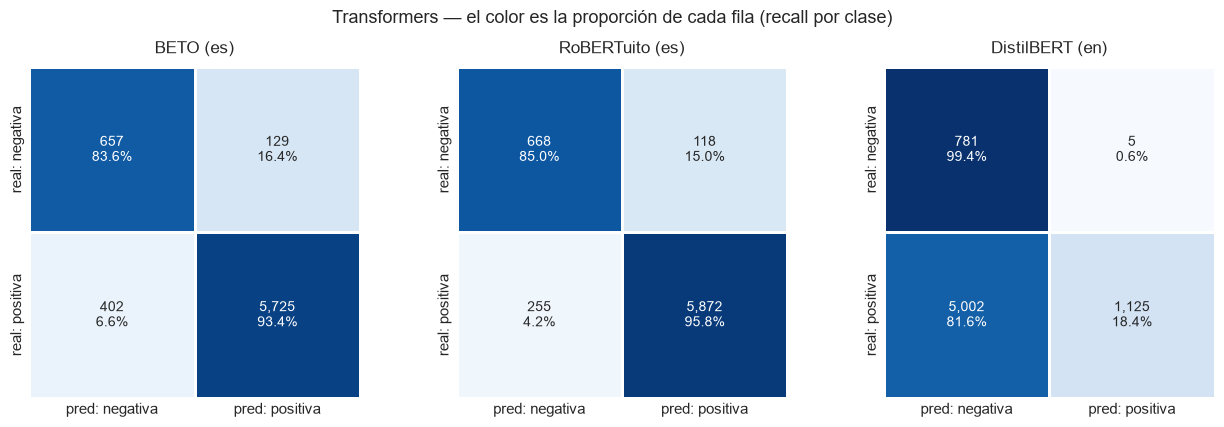

In [31]:
# === Matrices de confusión de los tres Transformers ===

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

for ax, (titulo, nombre) in zip(axes, [
    ("BETO (es)", MODELO),
    ("RoBERTuito (es)", MODELO_ROBERTUITO),
    ("DistilBERT (en)", MODELO_DISTIL),
]):
    matriz = confusion_matrix(y_test, predicciones_por_modelo[nombre], labels=etiquetas)
    proporcion = matriz / matriz.sum(axis=1, keepdims=True)
    anotaciones = [
        [f"{matriz[i, j]:,}\n{proporcion[i, j]:.1%}" for j in range(matriz.shape[1])]
        for i in range(matriz.shape[0])
    ]
    sns.heatmap(
        proporcion, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=1,
        cbar=False, square=True, linewidths=2, linecolor="white",
        xticklabels=[f"pred: {e}" for e in etiquetas],
        yticklabels=[f"real: {e}" for e in etiquetas],
        annot_kws={"fontsize": 10}, ax=ax,
    )
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.tick_params(length=0)

fig.suptitle(
    "Transformers — el color es la proporción de cada fila (recall por clase)",
    fontsize=13,
)
fig.tight_layout()
plt.show()